# 21 · The conversion corridor: trim through the transition, computed from the sized aircraft

A tiltrotor converts between helicopter mode (nacelles at 90°) and airplane mode (0°). At each nacelle angle there is a band of airspeeds in which
the aircraft can hold steady level flight: too slow and the wing cannot help, the nose has to pitch up too far to cancel forward thrust, or the
controls run out; too fast and the rotors, edgewise to the flow, flap and load the hubs and pylons. That band, plotted against nacelle angle, is
the **conversion corridor**. Every tiltrotor has one (the XV-15's is the classic picture) and every transition must stay inside it.

The sizing never sees the corridor: it works with hover and airplane-mode points only. `trajectory/corridor.py` (308 lines, plan 039) computes it
**after sizing**, from the sized aircraft, by solving level-flight trims. This notebook covers it end to end.

**In this notebook**
1. The trim problem: unknowns, equations, the rotor moment, the limits.
2. The geometry the moment balance needs, from the sized aircraft.
3. One trim, read in full; then trims along a speed sweep, to see where each limit bites.
4. Corridor bounds: airspeed as a variable; the computed corridor and its binding limits.
5. Computed versus assumed (XV-15-shaped) corridor.
6. Sensitivities: control limits, the edgewise limit, mass, CG and altitude.
7. Pitch authority near hover.
8. Limits and next steps.

**Run time:** about 30 seconds (each corridor is about a second; tutorial 19's design comes from the cache).

In [1]:
from tutorial_helpers import *
import numpy as onp
import inspect
from dataclasses import replace
from examples.halo_sizing import HaloRequirements, HaloAssumptions, solve_halo_sizing
requirements = HaloRequirements()
reference = cached("reference_scholz", lambda: solve_halo_sizing(requirements, replace(HaloAssumptions(), aerodynamics_model="scholz")))
counts = {name: whole for name, (relaxed, whole) in reference.machine_units.items()}
assumptions = replace(HaloAssumptions(), aerodynamics_model="scholz", count_units_motor=counts["motor"],
                      count_units_generator=counts["generator"])
print(f"the sized aircraft: {lb(reference.mass_takeoff_kg):,.0f} lb, wing {reference.design.area_wing_m2:.1f} m2, rotor radius "
      f"{reference.radius_rotor_m:.2f} m, design tip speed {reference.design.speed_tip_m_s:.0f} m/s")

[reference_scholz: computed in 1.0 min and cached]
the sized aircraft: 15,134 lb, wing 23.2 m2, rotor radius 4.83 m, design tip speed 238 m/s


## 1. The trim problem

At nacelle angle $\tau$ (90° hover) and airspeed $V$, in steady level flight (flight-path angle zero, so attitude = angle of attack $\alpha$):

$$F_x = nT(1 - f_\text{dl})\cos(\alpha + \tau + \theta) - D = 0$$
$$F_z = nT(1 - f_\text{dl})\sin(\alpha + \tau + \theta) + L + L_\text{tail}(\delta) - W = 0$$
$$M_y = M_\text{aero}(\alpha, \delta) + M_\text{rotor}(T, \tau, \theta) = 0$$

| Unknown | Meaning |
|---|---|
| $T$ | thrust per rotor |
| $\alpha$ | attitude (pitch) |
| $\delta$ | tail (ruddervator) deflection |
| $\theta$ | **rotor disc tilt**: tilt of the tip-path plane from the shaft, $\theta = f\,\theta_\text{max}\sin\tau$, washing out toward airplane mode (a trim-authority limit, not a structural stop) |

Three equations, four unknowns: one freedom remains, and the trim spends it on **least rotor power** (with a tiny penalty on disc tilt). Forces come
from `TiltrotorPointMass` (tutorial 22) with the thrust along the tip-path plane; the tail-deflection lift and the aerodynamic moment from
`LongitudinalStability` (tutorial 14); the rotor moment from the thrust acting at the hub, a mast length from the conversion spindle along the
shaft:

$$M_\text{rotor} = nT\big(x_\text{fwd,hub}\sin(\tau + \theta) - z_\text{up,hub}\cos(\tau + \theta)\big)$$

with the hub position relative to the CG. Thrust up ahead of the CG, or forward below it, pitches nose up.

The free-body diagram below names every angle, force and moment in those equations. It is drawn for a general flight path, with exaggerated angles,
so the three attitude angles are distinct:

- **gamma** is the flight-path angle (horizon to velocity), **alpha** the angle of attack (velocity to body x-axis), **pitch Theta = alpha + gamma**
  (horizon to body x-axis). The corridor trims **level flight, gamma = 0, so pitch = angle of attack**: `TrimPoint.pitch_deg` is both.
- **tau** is the nacelle angle, measured from the body x-axis to the shaft (0 = airplane mode, 90 = hover).
- **theta_d** is the disc tilt, measured from the shaft to the tip-path-plane normal, which is the thrust direction. It is a trim control whose authority
  washes out as sin(tau).
- **delta** is the ruddervator deflection; it adds tail lift L_tail.
- The thrust acts at the hub, a mast length out along the shaft from the spindle; its moment about the CG is M_rotor.
- The inset splits the velocity at the rotor into the **axial** part V cos(alpha + tau), which is all the rotor power model sees, and the **edgewise**
  part V sin(alpha + tau), which only enters through the edgewise advance-ratio limit.


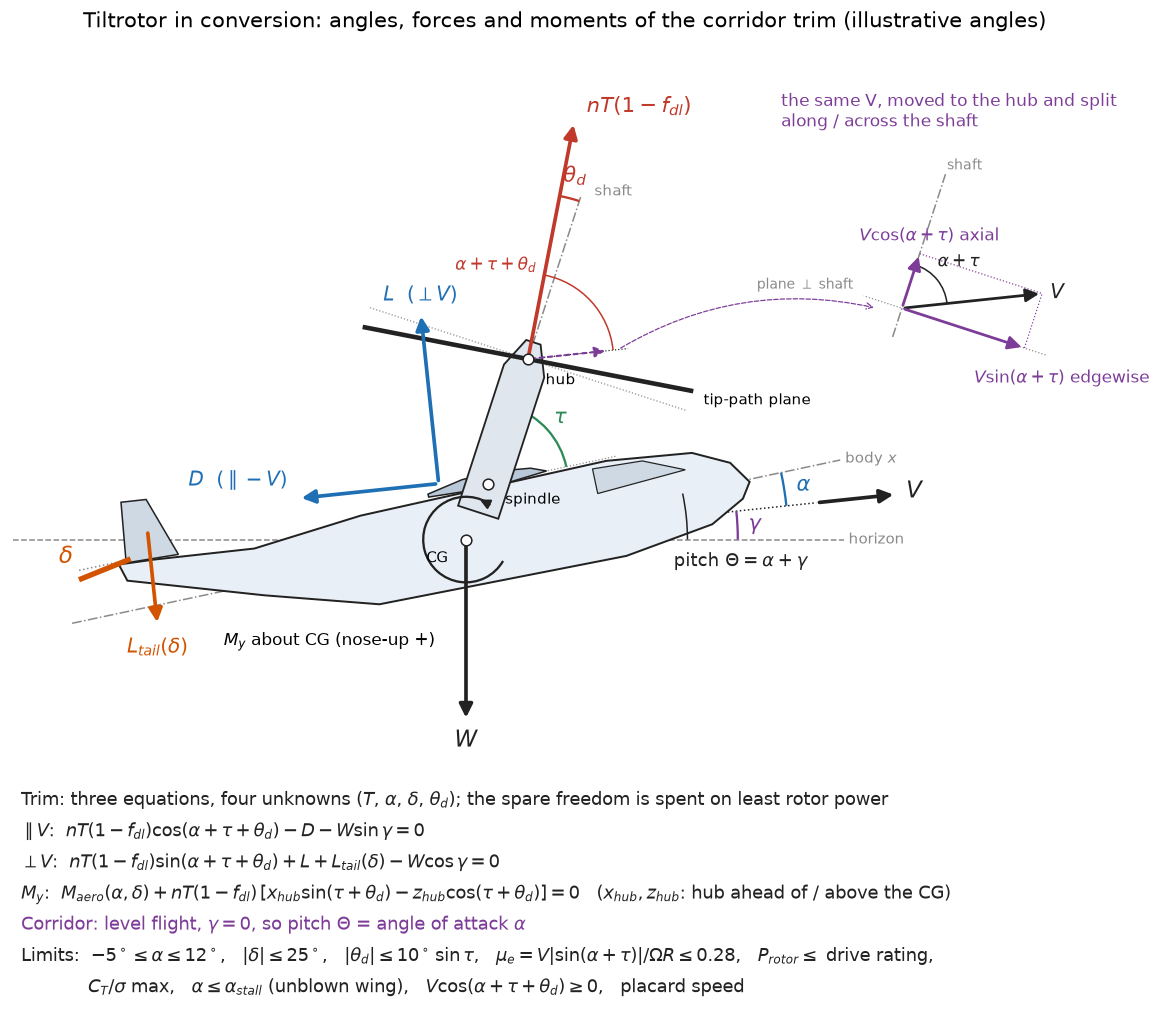

In [2]:
from examples.halo_conversion_corridor import plot_trim_free_body
fig, ax = plt.subplots(figsize=(12, 9.5))
plot_trim_free_body(ax=ax)
plt.tight_layout(); plt.show()


In [3]:
from aircraft_closure.trajectory.corridor import (moment_rotor_Nm, TrimGeometry, CorridorLimits, build_trim, solve_trim,
                                                  solve_corridor_bound, solve_corridor, ComputedCorridor)
print(inspect.getsource(moment_rotor_Nm))
geometry_demo = TrimGeometry(x_cg_m=5.0, z_cg_m=0.8, x_spindle_m=5.0, z_spindle_m=1.2, length_mast_m=1.0)
for tau_deg, theta_deg in ((90.0, 0.0), (90.0, 5.0), (0.0, 0.0)):
    print(f"tau {tau_deg:4.0f}, disc tilt {theta_deg:3.0f}: moment per 10 kN thrust = "
          f"{moment_rotor_Nm(10e3, tau_deg, tau_deg + theta_deg, geometry_demo):+8.0f} N m (positive nose up)")
check("hover thrust through a spindle over the CG gives no moment", abs(moment_rotor_Nm(10e3, 90.0, 90.0, geometry_demo)) < 1e-9)

def moment_rotor_Nm(thrust_total_N, angle_shaft_deg, angle_tip_path_deg, geometry):
    """Nose-up pitching moment about the CG of the rotors' thrust acting at the hubs.

    `angle_shaft_deg`: nacelle angle from the fuselage x-axis (90 deg hover); `angle_tip_path_deg`: the thrust's
    angle (shaft + disc tilt). Thrust up ahead of the CG or forward below it pitches nose-up.
    """
    forward_hub_m = (geometry.x_cg_m - geometry.x_spindle_m) + geometry.length_mast_m * np.cosd(angle_shaft_deg)
    up_hub_m = (geometry.z_spindle_m - geometry.z_cg_m) + geometry.length_mast_m * np.sind(angle_shaft_deg)
    return thrust_total_N * (forward_hub_m * np.sind(angle_tip_path_deg) - up_hub_m * np.cosd(angle_tip_path_deg))

tau   90, disc tilt   0: moment per 10 kN thrust =       -0 N m (positive nose up)
tau   90, disc tilt   5: moment per 10 kN thrust =    +1220 N m (positive nose up)
tau    0, disc tilt   0: moment per 10 kN thrust =    -4000 N m (positive nose up)
PASS  hover thrust through a

In hover with the spindle over the CG, thrust passes through the CG: no moment. A positive disc tilt at 90° (tip-path angle 95°, the disc tilted
aft) gives the thrust an aft component acting at the hub, above the CG: nose up. In airplane mode the thrust line passes above the CG: nose down.

**The limits** (`CorridorLimits`), each a normalized margin $\ge 0$; the ones the user set or accepted are noted (plan 039):

In [4]:
limits_default = CorridorLimits()
print(limits_default)

CorridorLimits(pitch_min_deg=-5.0, pitch_max_deg=12.0, deflection_max_tail_deg=25.0, tilt_max_disc_deg=10.0, advance_ratio_edgewise_max=0.28, velocity_placard_m_s=None, blade_loading_max=None, power_shaft_max_rotor_W=None)


| Limit | Default | Typically sets |
|---|---|---|
| attitude band | −5° to +12° | the low-speed side at small nacelle angles (forward thrust can only be cancelled by drag or nose-up pitch) |
| ruddervator deflection | ±25° (user decision) | pitch authority |
| disc tilt | ±10° × sin τ | pitch authority in helicopter mode |
| wing stall | the aerodynamics model's stall angle, free stream, above 10 m/s | low-speed side when wing-borne |
| edgewise advance ratio $V\sin(\alpha + \tau)/\Omega R$ | 0.28 | **high-speed side at high nacelle angles** (flapping, hub and pylon loads proxy; bounds the XV-15 corridor there) |
| rotor shaft power | the drive rating | high-speed side toward airplane mode |
| blade loading $C_T/\sigma$ | the rotor's limit | low speed, high attitude |
| placard speed | 1.1 × the 210 kt requirement here | airplane-mode high side |
| momentum validity $V\cos(\alpha + \tau + \theta) \ge 0$ | | no flow up through the disk |

## 2. Geometry from the sized aircraft

The moment balance needs the CG and the spindle. `examples/halo_conversion_corridor.py: halo_corridor_case` builds them from a sizing result: the
numeric aircraft, its mass breakdown at the design condition (CG), the spindle at the wing quarter root chord (where the rotors sit), the mast length,
the limits with a placard at 1.1 × the speed requirement, and the hover rotor speed held throughout:

In [5]:
from examples.halo_conversion_corridor import halo_corridor_case, tilts_deg
from aircraft_closure.controls.stability import LongitudinalStability
model, geometry, limits, speed_rotor_rad_s = halo_corridor_case(reference, requirements, assumptions)
stability = LongitudinalStability()
common = dict(mass_kg=reference.mass_takeoff_kg, altitude_m=0.0, speed_rotor_rad_s=speed_rotor_rad_s)
print(geometry)
print(f"placard {limits.velocity_placard_m_s / u.knot:.0f} kt; rotor speed {speed_rotor_rad_s:.1f} rad/s "
      f"(tip {speed_rotor_rad_s * model.instance('propulsor').radius_m():.0f} m/s)")
check("the sizing's hover trim put the CG under the spindle", abs(geometry.x_cg_m - geometry.x_spindle_m) < 1e-6)

TrimGeometry(x_cg_m=5.111290540691265, z_cg_m=0.7808248226910185, x_spindle_m=np.float64(5.111290540691265), z_spindle_m=1.2, length_mast_m=1.0)
placard 231 kt; rotor speed 49.4 rad/s (tip 238 m/s)
PASS  the sizing's hover trim put the CG under the spindle


The CG sits exactly under the spindle in x: that is the sizing's hover pitch-trim equality (tutorials 12, 14) at work. It sits about 0.4 m below the
wing, so forward thrust in airplane mode, acting above the CG, pitches the nose down.

## 3. One trim, then a speed sweep

`build_trim` adds one trim to an Opti (variables: pitch, thrust, tail deflection, disc-tilt fraction) and constrains every limit; `solve_trim` solves it
for least power and returns a `TrimPoint` with every margin:

In [6]:
trim = solve_trim(model, stability, geometry, limits, velocity_m_s=100 * u.knot, tilt_deg=60.0, **common)
print(f"60 deg, 100 kt: pitch {trim.pitch_deg:.2f} deg, thrust {trim.thrust_per_rotor_N:,.0f} N/rotor, tail {trim.deflection_tail_deg:.2f} deg, "
      f"disc tilt {trim.tilt_disc_deg:.2f} deg, {trim.power_shaft_rotor_W / 1e3:.0f} kW/rotor")
print(f"wing lift {trim.lift_wing_N:,.0f} N of weight {reference.mass_takeoff_kg * 9.80665:,.0f} N; download {trim.download_fraction:.3f}; "
      f"blown-wing local alpha {trim.alpha_local_blown_deg:.1f} deg (reported, not limited)")
for name, margin in sorted(trim.margins.items(), key=lambda item: item[1]):
    print(f"   {margin:+.3f}  {name}")

60 deg, 100 kt: pitch 10.82 deg, thrust 12,818 N/rotor, tail -8.00 deg, disc tilt 7.35 deg, 308 kW/rotor
wing lift 44,243 N of weight 67,320 N; download 0.002; blown-wing local alpha 1.1 deg (reported, not limited)
   +0.044  inflow_through_disk
   +0.118  pitch_max
   +0.280  disc_tilt
   +0.411  wing_stall
   +0.469  edgewise_advance_ratio
   +0.567  placard_speed
   +0.584  rotor_power
   +0.700  blade_loading
   +0.898  tail_deflection
   +1.582  pitch_min


Now sweep the airspeed at fixed nacelle angles. Each point is a separate least-power trim; where a trim does not exist the point is missing. The
corridor's edges at that angle appear as the ends of each curve:

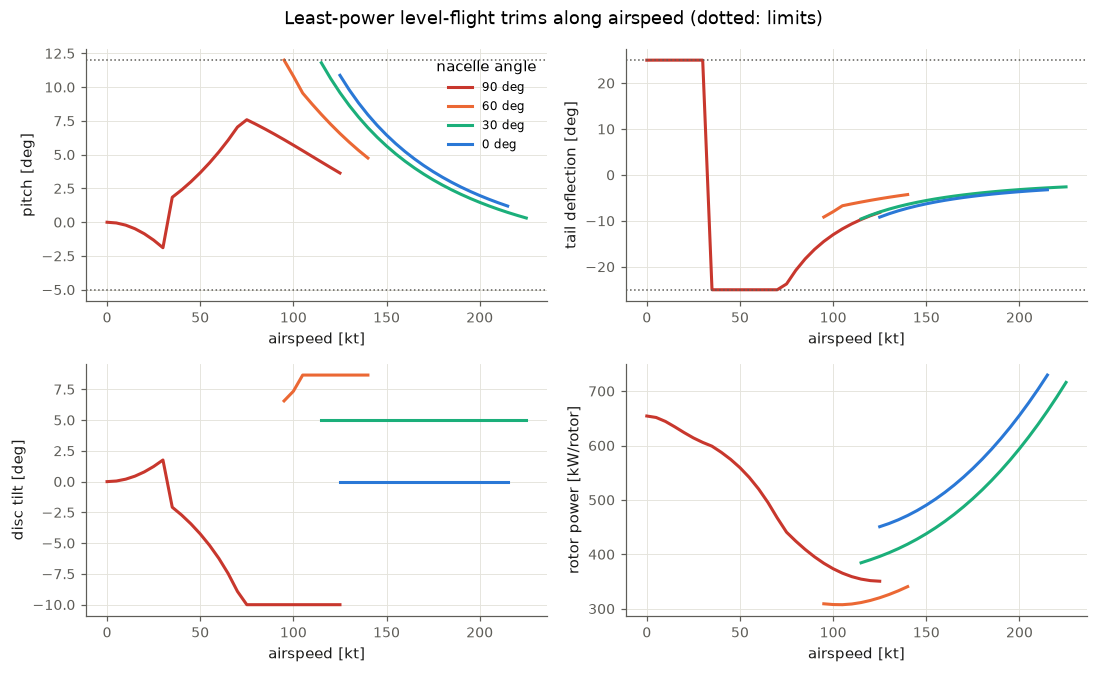

In [7]:
sweep = {}
with quiet_solver():
    for tau_deg in (90.0, 60.0, 30.0, 0.0):
        rows = []
        for v_kt in onp.arange(0, 240, 5):
            try:
                t_ = solve_trim(model, stability, geometry, limits, velocity_m_s=max(v_kt, 0.5) * u.knot, tilt_deg=tau_deg, **common)
                rows.append((v_kt, t_.pitch_deg, t_.deflection_tail_deg, t_.tilt_disc_deg, t_.power_shaft_rotor_W / 1e3, t_.advance_ratio_edgewise))
            except RuntimeError:
                pass
        sweep[tau_deg] = onp.array(rows)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for (tau_deg, rows), color in zip(sweep.items(), (red, orange, aqua, blue)):
    for ax, column, label in ((axes[0, 0], 1, "pitch [deg]"), (axes[0, 1], 2, "tail deflection [deg]"), (axes[1, 0], 3, "disc tilt [deg]"),
                              (axes[1, 1], 4, "rotor power [kW/rotor]")):
        ax.plot(rows[:, 0], rows[:, column], color=color, lw=2, label=f"{tau_deg:.0f} deg")
        ax.set(xlabel="airspeed [kt]", ylabel=label)
axes[0, 0].axhline(limits.pitch_max_deg, color=ink_muted, ls=":", lw=1); axes[0, 0].axhline(limits.pitch_min_deg, color=ink_muted, ls=":", lw=1)
axes[0, 1].axhline(-limits.deflection_max_tail_deg, color=ink_muted, ls=":", lw=1); axes[0, 1].axhline(limits.deflection_max_tail_deg, color=ink_muted, ls=":", lw=1)
axes[0, 0].legend(title="nacelle angle", fontsize=8); fig.suptitle("Least-power level-flight trims along airspeed (dotted: limits)")
plt.tight_layout(); plt.show()

Read the curves:

- **90° (helicopter):** power falls from hover with speed (induced power drops); disc tilt and tail trim the moment; the curve ends at the high side,
  where the edgewise advance ratio reaches 0.28.
- **60° and 30°:** no trims at low speed: with the rotors tilted forward, their forward thrust can only be cancelled by drag or a nose-up attitude,
  and the attitude limit (+12°) runs out. That is the low-speed side.
- **0° (airplane):** trims start near the wing-borne stall/attitude speed and end at rotor power or the placard.

One more thing to notice: at 90° below about 35 kt the tail deflection sits at +25°, then jumps to −25°. At those speeds the tail has almost no dynamic
pressure, so its deflection barely affects the moment, and the least-power objective does not price it. The solver leaves it at whichever bound it reaches.
It is a **degenerate direction** of the trim (a variable with almost no effect and no cost), not a control demand. Section 7 comes back to this.

## 4. Corridor bounds

`solve_corridor_bound` makes the airspeed itself an Opti variable and minimizes it (low side) or maximizes it (high side), with the trim equations and
every limit as constraints. The limit with zero margin at the optimum is the binding one: the answer says not only where the edge is but **what sets
it**. `solve_corridor` does that at each nacelle angle:

In [8]:
print(inspect.getsource(solve_corridor_bound)[:1600])

def solve_corridor_bound(model, stability, geometry, limits, *, mass_kg, tilt_deg, altitude_m, speed_rotor_rad_s,
                         side, velocity_guess_m_s=40.0, velocity_max_m_s=150.0, verbose=False):
    """The least ("low") or greatest ("high") level-flight trim airspeed at a nacelle angle."""
    if side not in ("low", "high"):
        raise ValueError(f"Unknown side '{side}'.")
    opti = asb.Opti()
    velocity_m_s = opti.variable(init_guess=velocity_guess_m_s, scale=50.0, lower_bound=0.0,
                                 upper_bound=velocity_max_m_s)
    point = build_trim(opti, model, stability, geometry, limits, mass_kg=mass_kg, velocity_m_s=velocity_m_s,
                       tilt_deg=tilt_deg, altitude_m=altitude_m, speed_rotor_rad_s=speed_rotor_rad_s)
    sign = 1.0 if side == "low" else -1.0
    opti.minimize(sign * velocity_m_s / 50.0 + 1e-3 * _power_objective(point, model))
    try:
        sol = opti.solve(verbose=verbose, max_iter=1000, behavior_on_failure="ra

 tilt  low kt  set by                       high kt  set by
    0   120.3  pitch_max                      217.0  rotor_power
   15   117.7  pitch_max, disc_tilt           221.3  disc_tilt, rotor_power
   30   114.2  pitch_max, disc_tilt           229.3  disc_tilt, rotor_power
   45   108.2  pitch_max, disc_tilt           175.5  disc_tilt, edgewise_advance_ratio
   60    90.8  pitch_max, disc_tilt           143.8  disc_tilt, edgewise_advance_ratio
   75    -0.0  hover                          133.8  disc_tilt, edgewise_advance_ratio
   90    -0.0  hover                          129.9  disc_tilt, edgewise_advance_ratio


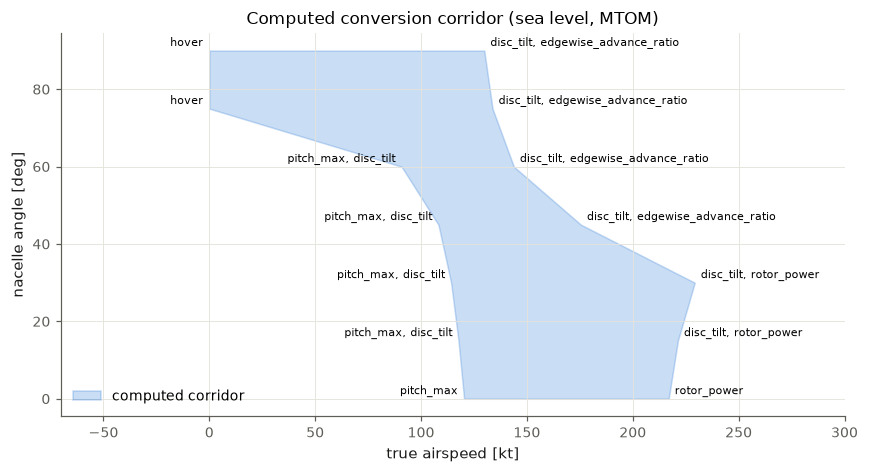

PASS  the high-speed side in helicopter mode is set by the edgewise advance ratio
PASS  the low-speed side at 30-60 deg is set by the attitude limit


In [9]:
def corridor_for(model_, geometry_, limits_, **kwargs):
    arguments = dict(common, **kwargs)
    with quiet_solver():
        return solve_corridor(model_, stability, geometry_, limits_, tilts_deg=tilts_deg,
                              velocity_max_m_s=1.05 * limits.velocity_placard_m_s, **arguments)

bounds = corridor_for(model, geometry, limits)
print(f"{'tilt':>5} {'low kt':>7}  {'set by':<28} {'high kt':>7}  set by")
for low, high in bounds:
    text = lambda b: "-" if b.trim is None else f"{b.velocity_m_s / u.knot:7.1f}"
    print(f"{low.tilt_deg:5.0f} {text(low)}  {', '.join(low.binding):<28} {text(high)}  {', '.join(high.binding)}")

def plot_corridor(ax, bounds_, color, label, annotate=False, alpha=0.25):
    pairs = [(lo, hi) for lo, hi in bounds_ if lo.trim is not None and hi.trim is not None]
    tilts = [lo.tilt_deg for lo, _ in pairs]
    ax.fill_betweenx(tilts, [lo.velocity_m_s / u.knot for lo, _ in pairs], [hi.velocity_m_s / u.knot for _, hi in pairs],
                     color=color, alpha=alpha, label=label)
    if annotate:
        for lo, hi in pairs:
            ax.annotate(", ".join(lo.binding), (lo.velocity_m_s / u.knot, lo.tilt_deg), xytext=(-4, 3), textcoords="offset points", ha="right", fontsize=7)
            ax.annotate(", ".join(hi.binding), (hi.velocity_m_s / u.knot, hi.tilt_deg), xytext=(4, 3), textcoords="offset points", fontsize=7)

fig, ax = plt.subplots(figsize=(8, 4.4))
plot_corridor(ax, bounds, blue, "computed corridor", annotate=True)
ax.set(xlabel="true airspeed [kt]", ylabel="nacelle angle [deg]", xlim=(-70, 300), title="Computed conversion corridor (sea level, MTOM)")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()
binding_high_90 = bounds[-1][1].binding
check("the high-speed side in helicopter mode is set by the edgewise advance ratio", "edgewise_advance_ratio" in binding_high_90)
check("the low-speed side at 30-60 deg is set by the attitude limit", all("pitch_max" in lo.binding for lo, _ in bounds if 30 <= lo.tilt_deg <= 60))

This matches what was found on the full reference (plan 039): the high side is edgewise-limited from 45° up (about 130 kt at 90°, close to the
XV-15's), and the low side is **attitude-limited, not stall-limited**. The user's remark that "stall is weird for wings in transition" is why stall is
applied only to the unblown wing: near hover the blown inboard wing sees the rotor downwash, which the download model already carries.


### Power required across the corridor

The bounds say *where* a trim exists; the power map says *what it costs*. `solve_power_map` takes the corridor bounds and solves the least-power trim
(`solve_trim`) at evenly spaced airspeeds between the low and high bound at each nacelle angle, just inside them (a trim exactly on a bound sits on a
limit). `plot_power_map` draws the total rotor shaft power (both rotors) as filled contours with labelled lines, over the corridor and its binding
limits. A finer nacelle-angle grid (every 7.5°) makes the contours smooth; about 150 trims, a few seconds.

Read it like a helicopter power curve stretched across the conversion. Hover (top left) needs about 1,300 kW at sea level, below the drive rating:
the rating is set by the 4,000 ft hot-day hover in sizing, not by this sea-level case. Power falls as speed builds and the wing takes the weight (the
**bucket**, the least-power region at mid nacelle angles near 100 kt, under half of hover power). It rises again toward the airplane-mode high side,
where it reaches the drive rating, which is the "rotor power" limit setting that corridor edge.


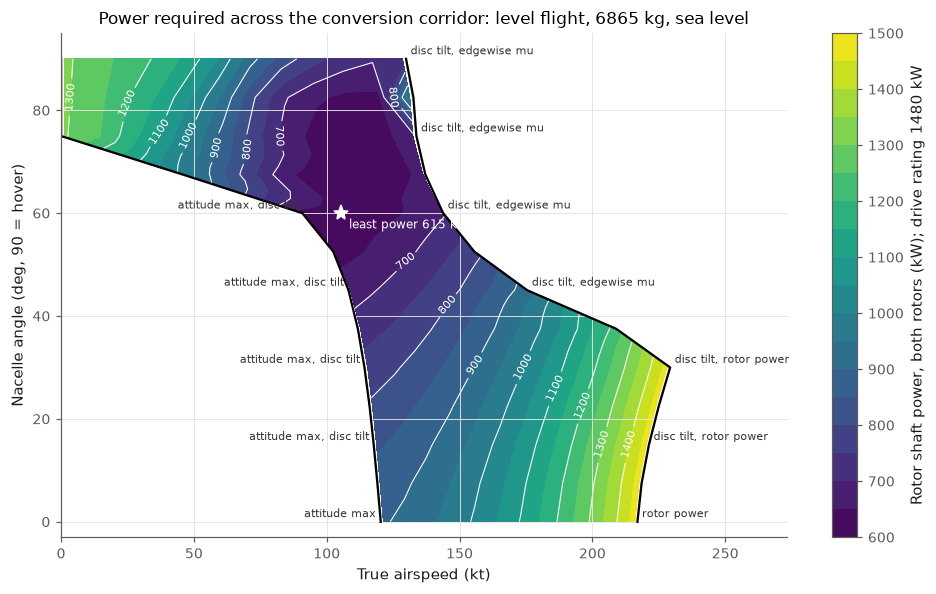

hover 1308 kW, least 615 kW (47% of hover)
PASS  every grid point inside the corridor trims
PASS  the least-power trim needs well under hover power (the bucket)


In [10]:
from aircraft_closure.trajectory.corridor import solve_power_map
from examples.halo_conversion_corridor import plot_power_map, tilts_map_deg
with quiet_solver():
    bounds_fine = solve_corridor(model, stability, geometry, limits, tilts_deg=tilts_map_deg,
                                 velocity_max_m_s=1.05 * limits.velocity_placard_m_s, **common)
    power_map = solve_power_map(model, stability, geometry, limits, bounds_fine, **common)
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_power_map(power_map, bounds_fine, reference, model, None, ax=ax)
plt.tight_layout(); plt.show()
power_kW = model.count("propulsor") * onp.array(power_map.values("power_shaft_rotor_W")) / 1e3
hover_kW = power_kW[-1][0]
print(f"hover {hover_kW:.0f} kW, least {onp.nanmin(power_kW):.0f} kW ({onp.nanmin(power_kW) / hover_kW:.0%} of hover)")
check("every grid point inside the corridor trims", not onp.isnan(power_kW).any())
check("the least-power trim needs well under hover power (the bucket)", onp.nanmin(power_kW) < 0.6 * hover_kW)


## 5. Computed versus assumed corridor

Before plan 039 the trajectory layer used an **assumed** corridor shaped like the XV-15's (`trajectory/tiltrotor.py: ConversionCorridor`): low side
$V \ge V_\text{stall}\cos\tau$, high side a quadratic fit from 115 kt at 90° to 180 kt at 0°. Overlay it on the computed one:

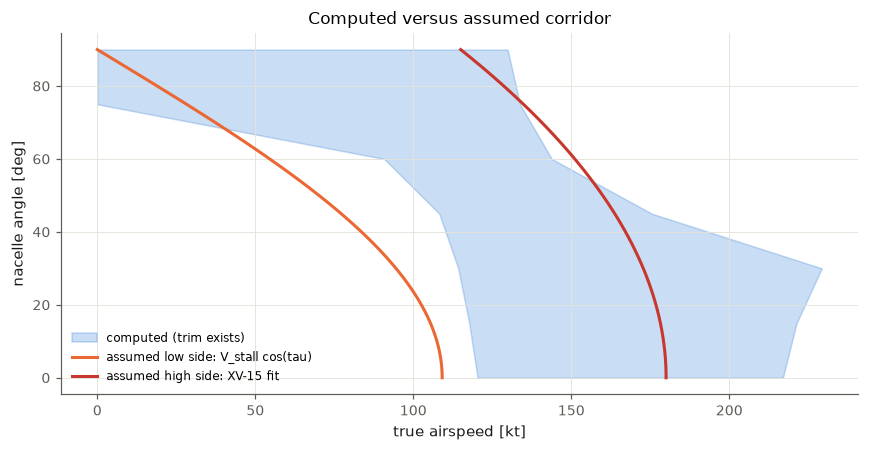

In [11]:
from aircraft_closure.trajectory.tiltrotor import ConversionCorridor
assumed = ConversionCorridor(velocity_stall_m_s=float(model.velocity_stall_m_s(reference.mass_takeoff_kg, 0.0)))
taus = onp.linspace(0, 90, 50)
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_corridor(ax, bounds, blue, "computed (trim exists)")
ax.plot(assumed.velocity_min_m_s(taus) / u.knot, taus, color=orange, lw=2, label="assumed low side: V_stall cos(tau)")
ax.plot(assumed.velocity_max_m_s(taus) / u.knot, taus, color=red, lw=2, label="assumed high side: XV-15 fit")
ax.set(xlabel="true airspeed [kt]", ylabel="nacelle angle [deg]", title="Computed versus assumed corridor")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

The computed corridor is narrower on the low side at mid nacelle angles (attitude-limited) and wider on the high side toward airplane mode (rotor power and
placard rather than the XV-15's structural limits). Both differences are physics the assumed shape could not know. Tutorial 22 flies transitions inside the
computed one.

## 6. Sensitivities

Each corridor solve takes about a second, so trades are cheap. The question a controls or rotor engineer will ask: **which limit, if relaxed, widens the
corridor where it matters?**

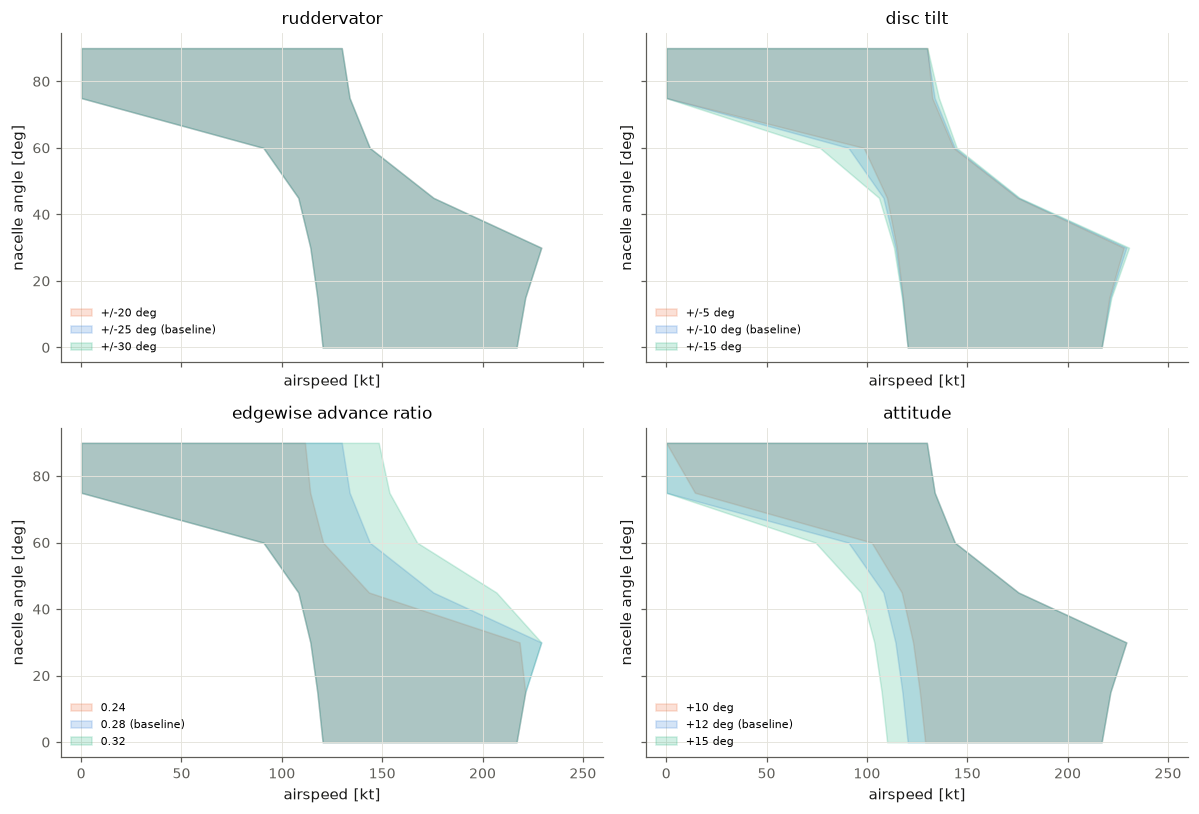

high side at 90 deg against the edgewise limit: {'0.24': 111.5, '0.28 (baseline)': 129.9, '0.32': 148.3}
PASS  a looser edgewise limit raises the helicopter-mode high side
low side at 45 deg against the attitude limit: {'+10 deg': 117.4, '+12 deg (baseline)': 108.2, '+15 deg': 97.0}
PASS  more nose-up attitude allowed lowers the mid-conversion low side


In [12]:
studies = {
    "ruddervator": [("+/-20 deg", replace(limits, deflection_max_tail_deg=20.0)), ("+/-25 deg (baseline)", limits),
                    ("+/-30 deg", replace(limits, deflection_max_tail_deg=30.0))],
    "disc tilt": [("+/-5 deg", replace(limits, tilt_max_disc_deg=5.0)), ("+/-10 deg (baseline)", limits),
                  ("+/-15 deg", replace(limits, tilt_max_disc_deg=15.0))],
    "edgewise advance ratio": [("0.24", replace(limits, advance_ratio_edgewise_max=0.24)), ("0.28 (baseline)", limits),
                               ("0.32", replace(limits, advance_ratio_edgewise_max=0.32))],
    "attitude": [("+10 deg", replace(limits, pitch_max_deg=10.0)), ("+12 deg (baseline)", limits), ("+15 deg", replace(limits, pitch_max_deg=15.0))],
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
summary = {}
for ax, (study, cases) in zip(axes.ravel(), studies.items()):
    for (label, limits_case), color in zip(cases, (orange, blue, aqua)):
        b = corridor_for(model, geometry, limits_case)
        plot_corridor(ax, b, color, label, alpha=0.2)
        summary[(study, label)] = b
    ax.set(title=study, xlabel="airspeed [kt]", ylabel="nacelle angle [deg]", xlim=(-10, 260)); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

def width_kt(b, tau_deg):
    lo, hi = next(pair for pair in b if pair[0].tilt_deg == tau_deg)
    return None if lo.trim is None or hi.trim is None else (hi.velocity_m_s - lo.velocity_m_s) / u.knot

hi90 = {label: next(p for p in b if p[0].tilt_deg == 90.0)[1].velocity_m_s / u.knot for (study, label), b in summary.items() if study == "edgewise advance ratio"}
print("high side at 90 deg against the edgewise limit:", {k: round(v, 1) for k, v in hi90.items()})
check("a looser edgewise limit raises the helicopter-mode high side", hi90["0.32"] > hi90["0.28 (baseline)"] > hi90["0.24"])
lo45 = {label: next(p for p in b if p[0].tilt_deg == 45.0)[0].velocity_m_s / u.knot for (study, label), b in summary.items() if study == "attitude"}
print("low side at 45 deg against the attitude limit:", {k: round(v, 1) for k, v in lo45.items()})
check("more nose-up attitude allowed lowers the mid-conversion low side", lo45["+15 deg"] < lo45["+12 deg (baseline)"] < lo45["+10 deg"])

Mass, CG and altitude change the aircraft rather than the limits:

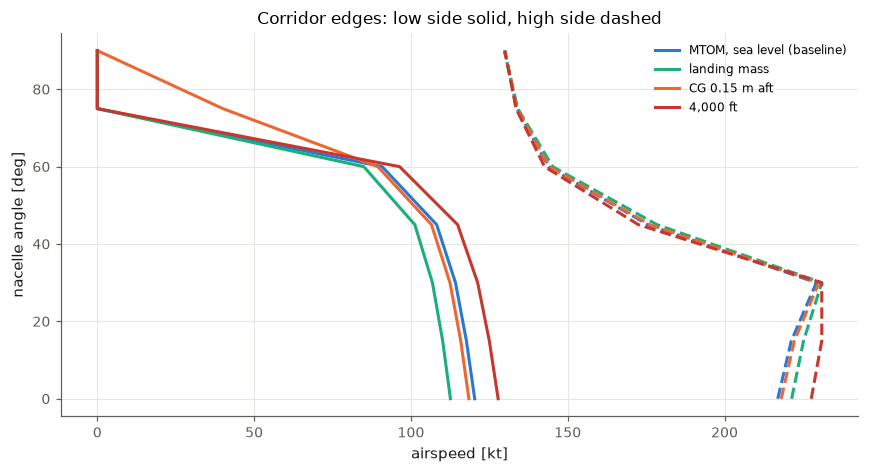

MTOM, sea level (baseline)   width at 60 deg:   53.0 kt; at 90 deg:  129.9 kt
landing mass                 width at 60 deg:   60.2 kt; at 90 deg:  129.8 kt
CG 0.15 m aft                width at 60 deg:   54.7 kt; at 90 deg:  129.8 kt
4,000 ft                     width at 60 deg:   46.2 kt; at 90 deg:  129.9 kt


In [13]:
mass_landing_kg = reference.mass_takeoff_kg - reference.mass_fuel_burnt_kg
cases = [("MTOM, sea level (baseline)", dict(), geometry), ("landing mass", dict(mass_kg=mass_landing_kg), geometry),
         ("CG 0.15 m aft", dict(), replace(geometry, x_cg_m=geometry.x_cg_m + 0.15)),
         ("4,000 ft", dict(altitude_m=4000 * u.foot), geometry)]
fig, ax = plt.subplots(figsize=(8, 4.4))
results_cases = {}
for (label, kwargs, geometry_case), color in zip(cases, (blue, aqua, orange, red)):
    b = corridor_for(model, geometry_case, limits, **kwargs)
    results_cases[label] = b
    pairs = [(lo, hi) for lo, hi in b if lo.trim is not None and hi.trim is not None]
    ax.plot([lo.velocity_m_s / u.knot for lo, _ in pairs], [lo.tilt_deg for lo, _ in pairs], color=color, lw=2, label=label)
    ax.plot([hi.velocity_m_s / u.knot for _, hi in pairs], [hi.tilt_deg for _, hi in pairs], color=color, lw=2, ls="--")
ax.set(xlabel="airspeed [kt]", ylabel="nacelle angle [deg]", title="Corridor edges: low side solid, high side dashed")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for label, b in results_cases.items():
    print(f"{label:<28} width at 60 deg: {width_kt(b, 60.0) or float('nan'):6.1f} kt; at 90 deg: {width_kt(b, 90.0) or float('nan'):6.1f} kt")

## 7. Pitch authority near hover

With the nacelles at 90°, pitch is trimmed by the ruddervator (effective only with dynamic pressure) and by disc tilt (effective with thrust). At low speed
disc tilt does the work; as speed builds, the tail takes over. Plot what the least-power trim uses along the 90° sweep, remembering section 3: below about
35 kt the tail deflection is degenerate (no effect, no cost), so only disc tilt is meaningful there.

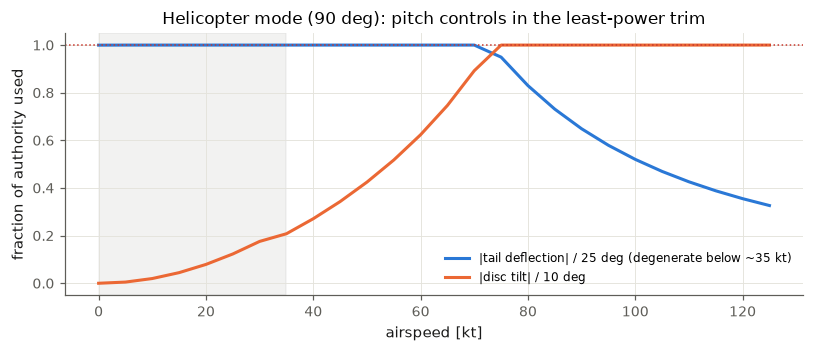

combined pitch-control use peaks at 75 kt: tail -23.7 deg, disc tilt -10.0 deg (sum of fractions 1.95 of 2)
PASS  combined pitch-control use peaks between 60 and 90 kt, above 1.8 of 2


In [14]:
rows = sweep[90.0]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.plot(rows[:, 0], onp.abs(rows[:, 2]) / limits.deflection_max_tail_deg, color=blue, lw=2, label="|tail deflection| / 25 deg (degenerate below ~35 kt)")
ax.plot(rows[:, 0], onp.abs(rows[:, 3]) / limits.tilt_max_disc_deg, color=orange, lw=2, label="|disc tilt| / 10 deg")
ax.axvspan(0, 35, color=ink_muted, alpha=0.08)
ax.axhline(1.0, color=red, ls=":", lw=1)
ax.set(xlabel="airspeed [kt]", ylabel="fraction of authority used", title="Helicopter mode (90 deg): pitch controls in the least-power trim")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
combined = onp.abs(rows[:, 2]) / limits.deflection_max_tail_deg + onp.abs(rows[:, 3]) / limits.tilt_max_disc_deg
mask = rows[:, 0] > 35            # the tail deflection is degenerate below about 35 kt
k = onp.argmax(onp.where(mask, combined, 0.0))
print(f"combined pitch-control use peaks at {rows[k, 0]:.0f} kt: tail {rows[k, 2]:+.1f} deg, disc tilt {rows[k, 3]:+.1f} deg "
      f"(sum of fractions {combined[k]:.2f} of 2)")
check("combined pitch-control use peaks between 60 and 90 kt, above 1.8 of 2", 60 <= rows[k, 0] <= 90 and combined[k] > 1.8)

Read it with the objective in mind. Disc tilt carries a small penalty in the least-power trim, so between about 35 and 72 kt the trim uses the
ruddervator first, to its −25° limit, and disc tilt only as much as needed. Beyond about 73 kt disc tilt reaches −10° and the tail backs off as dynamic
pressure grows. **The combined use peaks near 72-75 kt**, with both controls at or next to their limits. That is where helicopter-mode pitch authority is
tightest (the full reference, plan 039, put it around 65 kt). A control engineer would study this band first, with the linearized plant around these trims.

## Limits and next steps

**What it can't do** (from the module docstring and plan 039)

- **No rotor in-plane (H) force** in edgewise flow: this drag would help cancel forward thrust, so the low side at 45-60° is likely too wide compared with the
  XV-15 (conservative only in one direction; the H-force is the first next step).
- **The rotor's edgewise flow does not change its power** (the point-mass model's axial-flow rotor, tutorial 22).
- **The tail sees the free stream**: no rotor wake or wing-downwash change in conversion.
- **The CG does not move with the nacelles**; a gimballed rotor carries no hub moment, so disc tilt acts only by tilting the thrust.
- **Steady level flight only**: no climbing or accelerating trims, no lateral-directional trim.
- **Edgewise advance ratio is a proxy** for flapping, hub and pylon loads, with an assumed limit (0.28).
- **The corridor is not a sizing constraint**: if it were unacceptable, the remedy (more ruddervator, more disc tilt, a hub limit) would have to go back into the
  sizing as a requirement.

**What's next:** the rotor H-force; a rotor speed schedule through conversion; linearized longitudinal plants at the trim schedule (CasADi Jacobians of the same
equations); lateral-directional trim; the corridor as a sizing requirement where it matters.

## Summary

- A trim at (τ, V) has four unknowns (thrust, attitude, tail deflection, disc tilt), three equilibrium equations, and least power for the free one; every limit is a
  normalized margin.
- The corridor bound makes airspeed the variable and reports which limit sets each edge: on the Halo, attitude on the low side, edgewise advance ratio (helicopter
  side) and rotor power or placard (airplane side) on the high side.
- Corridor trades take seconds: the edgewise and attitude limits move the edges most directly.

## Check yourself

<details><summary>1. Why is the low-speed side at 45° set by attitude and not by stall?</summary>

At 45° the rotors produce a large forward thrust component. To fly level and slowly, that forward force must be cancelled by drag or by pitching the nose (and the thrust) up. The attitude limit (+12°) runs out before the wing reaches stall at those speeds.
</details>

<details><summary>2. A controls engineer asks for 10 kt more margin on the high side at 90°. What do you look at?</summary>

The binding limit there is the edgewise advance ratio (V sin(α + τ)/ΩR ≤ 0.28). Options: a higher rotor speed in conversion (tip speed, if the tip-Mach and power limits allow), a hub designed for more flapping (a higher limit, with loads data to back it), or converting earlier (a lower nacelle angle at that speed).
</details>

In [15]:
check_summary()

9 of 9 checks passed
